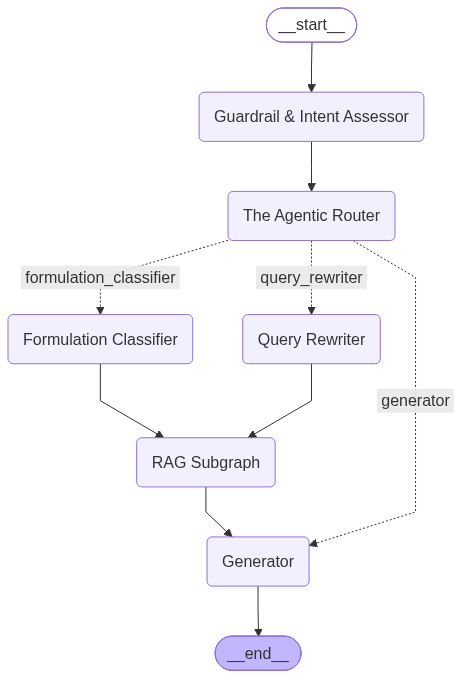

In [2]:
from typing import TypedDict, List
from langgraph.graph import StateGraph, START, END

# --- 1. State Schema ---
class GraphState(TypedDict):
    query: str
    chat_history: List[str]
    formulation_category: str
    ip_intent: str
    selected_namespaces: List[str]
    retrieved_context: List[str]
    citations: List[str]
    confidence_score: float
    response: str


# --- 2. Dummy Node Functions ---
def guardrail_intent_assessor(state: GraphState):
    pass

def agentic_router(state: GraphState):
    pass

def query_rewriter(state: GraphState):
    pass

def formulation_classifier(state: GraphState):
    pass

def generator(state: GraphState):
    pass

# RAG Subgraph Nodes
def multi_source_router(state: GraphState):
    pass

def query_refiner(state: GraphState):
    pass

def async_db_search(state: GraphState):
    pass

def rag_eval(state: GraphState):
    pass

def helper_injection(state: GraphState):
    pass


# --- 3. Build RAG Subgraph ---
rag_builder = StateGraph(GraphState)

rag_builder.add_node("Multi Source Router", multi_source_router)
rag_builder.add_node("Query Refiner", query_refiner)
rag_builder.add_node("Async DB Search", async_db_search)
rag_builder.add_node("RAG EVAL (single pass)", rag_eval)
rag_builder.add_node("Helper Injection", helper_injection)

rag_builder.add_edge(START, "Multi Source Router")
rag_builder.add_edge("Multi Source Router", "Query Refiner")
rag_builder.add_edge("Query Refiner", "Async DB Search")
rag_builder.add_edge("Async DB Search", "RAG EVAL (single pass)")
rag_builder.add_edge("RAG EVAL (single pass)", "Helper Injection")
rag_builder.add_edge("Helper Injection", END)

rag_subgraph = rag_builder.compile()


# --- 4. Routing Decision Logic (Dummy) ---
def route_decision(state: GraphState) -> str:
    # Dummy condition mapping to the 3 paths
    return "generator"


# --- 5. Build Main Graph ---
main_builder = StateGraph(GraphState)

main_builder.add_node("Guardrail & Intent Assessor", guardrail_intent_assessor)
main_builder.add_node("The Agentic Router", agentic_router)
main_builder.add_node("Query Rewriter", query_rewriter)
main_builder.add_node("Formulation Classifier", formulation_classifier)
main_builder.add_node("RAG Subgraph", rag_subgraph)
main_builder.add_node("Generator", generator)

# Edges
main_builder.add_edge(START, "Guardrail & Intent Assessor")
main_builder.add_edge("Guardrail & Intent Assessor", "The Agentic Router")

# 3-Way Split from Agentic Router
main_builder.add_conditional_edges(
    "The Agentic Router",
    route_decision,
    {
        "generator": "Generator",
        "query_rewriter": "Query Rewriter",
        "formulation_classifier": "Formulation Classifier",
    }
)

# Paths B & C converge into RAG Subgraph
main_builder.add_edge("Query Rewriter", "RAG Subgraph")
main_builder.add_edge("Formulation Classifier", "RAG Subgraph")

# RAG Subgraph output connects to Generator
main_builder.add_edge("RAG Subgraph", "Generator")
main_builder.add_edge("Generator", END)

app = main_builder.compile()

app

#### Rag Subgraph:

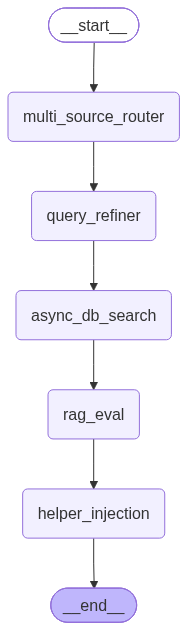

In [1]:
"""RAG Subgraph definition (Scatter-Gather Core)."""
from langgraph.graph import StateGraph, START, END
from core.state import GraphState
from nodes.rag.multi_source_router import multi_source_router_node
from nodes.rag.query_refiner import query_refiner_node
from nodes.rag.db_search import async_db_search_node
from nodes.rag.rag_eval import rag_eval_node
from nodes.rag.helper_injection import helper_injection_node

def create_rag_subgraph() -> StateGraph:
    """
    Builds the scatter-gather RAG Subgraph:
    Multi-Source Router -> Query Refiner -> Async DB Search -> RAG EVAL -> Helper Injection.
    """
    subgraph = StateGraph(GraphState)

    subgraph.add_node("multi_source_router", multi_source_router_node)
    subgraph.add_node("query_refiner", query_refiner_node)
    subgraph.add_node("async_db_search", async_db_search_node)
    subgraph.add_node("rag_eval", rag_eval_node)
    subgraph.add_node("helper_injection", helper_injection_node)

    subgraph.add_edge(START, "multi_source_router")
    subgraph.add_edge("multi_source_router", "query_refiner")
    subgraph.add_edge("query_refiner", "async_db_search")
    subgraph.add_edge("async_db_search", "rag_eval")
    subgraph.add_edge("rag_eval", "helper_injection")
    subgraph.add_edge("helper_injection", END)

    return subgraph.compile()

rag_subgraph = create_rag_subgraph()
rag_subgraph